<a href="https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/notebooks/04-treinar-segmentacao.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 4. Treinar a segmentação

O modelo pronto desenha pessoa, leito, cadeira e caminhão. Para desenhar uma trinca no concreto ou o contorno de uma estrutura numa foto clínica, o treino precisa de fotos em que o contorno já foi marcado.

O rótulo deixa de ser um retângulo. Cada objeto vira um polígono: a classe, e depois os pontos do contorno, todos entre 0 e 1.

O dataset pequeno é o `coco8-seg`: quatro fotos de treino e quatro de validação, já no formato certo. Serve para ver o processo. Ele não é um conjunto de hospital nem de canteiro. Um modelo bom pede centenas de contornos por classe.

> Aqui a GPU faz diferença: **Ambiente de execução → Alterar o tipo de ambiente → T4 GPU**.

In [1]:
!pip install -q ultralytics

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mascaras_originais(resultado):
    """Máscaras no tamanho da foto, como array booleano (n, altura, largura).

    A rede responde numa grade menor que a imagem. Aqui a máscara é esticada
    de volta ao tamanho original, para a área bater com os pixels da foto.
    """
    import cv2
    import numpy as np

    altura, largura = resultado.orig_shape
    if resultado.masks is None or len(resultado.masks) == 0:
        return np.zeros((0, altura, largura), dtype=bool)
    saida = []
    for mascara in resultado.masks.data.cpu().numpy():
        mascara = cv2.resize(mascara, (largura, altura), interpolation=cv2.INTER_NEAREST)
        saida.append(mascara > 0.5)
    return np.stack(saida)


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

## Como é um rótulo de segmentação

Uma linha por objeto. O primeiro número é a classe. O resto são pares `x y` do polígono. Uma caixa teria cinco números no total. Um contorno tem bem mais.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO
from ultralytics.utils import DATASETS_DIR

model = YOLO("yolov8n-seg.pt")

## Treinar

A chamada é a mesma do treino de detecção. Muda o peso inicial (`yolov8n-seg.pt`) e o yaml (`coco8-seg.yaml`). Três épocas com imagens de 320 px bastam para aparecer um `results.csv`. Não bastam para um modelo bom.

In [4]:
treino = model.train(
    data="coco8-seg.yaml",
    epochs=3,
    imgsz=320,
    batch=4,
    project="runs",
    name="coco8seg",
    exist_ok=True,
    plots=False,
    verbose=False,
)
pasta = Path(treino.save_dir)
print("Resultados em", pasta)

Ultralytics 8.4.184 🚀 Python-3.12.13 torch-2.14.1 CPU (Apple M4)



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             


...

YOLOv8n-seg summary (fused): 85 layers, 3,404,320 parameters, 0 gradients, 12.0 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 10.5it/s 0.1s

                   all          4         17      0.576      0.531       0.55      0.395      0.542      0.436      0.407      0.302


Speed: 0.1ms preprocess, 20.3ms inference, 0.0ms loss, 1.1ms postprocess per image


Resultados em runs/segment/runs/coco8seg


## O que o arquivo de rótulos tem

In [5]:
rotulo = sorted((DATASETS_DIR / "coco8-seg" / "labels" / "train").glob("*.txt"))[0]
linha = rotulo.read_text().splitlines()[0].split()
print(rotulo.name)
print(f"classe {linha[0]}, { (len(linha) - 1) // 2 } pontos no polígono")
print(" ".join(linha[:13]), "...")

000000000009.txt
classe 45, 12 pontos no polígono
45 0.782016 0.986521 0.937078 0.874167 0.957297 0.782021 0.950562 0.739333 0.825844 0.561792 0.714609 0.420229 ...


## A perda da máscara

Além da perda da caixa e da classe, o treino de segmentação tem `train/seg_loss`: o quanto o contorno previsto errou o contorno marcado. Com quatro fotos, a curva oscila. O que importa é saber em qual coluna ela mora.

 epoch  train/box_loss  train/seg_loss  train/cls_loss  metrics/mAP50(M)
     1         1.17930         3.04785         2.16309           0.47612
     2         0.94834         2.99077         2.30208           0.47612
     3         1.30574         3.07905         2.62342           0.47612


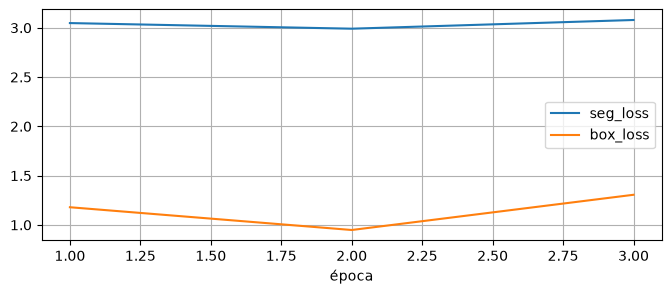

In [6]:
df = pd.read_csv(pasta / "results.csv")
df.columns = df.columns.str.strip()
colunas = ["epoch", "train/box_loss", "train/seg_loss", "train/cls_loss", "metrics/mAP50(M)"]
print(df[colunas].to_string(index=False))

plt.figure(figsize=(8, 3))
plt.plot(df["epoch"], df["train/seg_loss"], label="seg_loss")
plt.plot(df["epoch"], df["train/box_loss"], label="box_loss")
plt.xlabel("época")
plt.legend()
plt.grid(True)
plt.show()

## Usar o modelo treinado

O melhor peso fica em `weights/best.pt`. Ele carrega igual ao modelo original e devolve máscara do mesmo jeito.

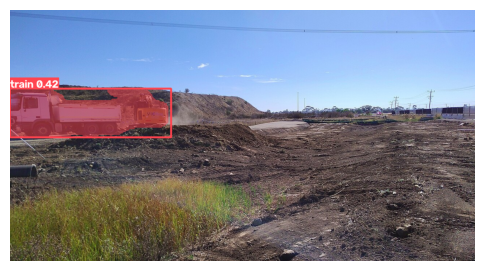

1 máscaras


In [7]:
melhor = YOLO(pasta / "weights" / "best.pt")
r = melhor("https://raw.githubusercontent.com/naubergois/curso-segmentacao-colab/main/midia/canteiro.jpg", verbose=False)[0]
plt.figure(figsize=(6, 8))
plt.imshow(r.plot()[:, :, ::-1])
plt.axis("off")
plt.show()
print(0 if r.masks is None else len(r.masks), "máscaras")

## Exercícios

Seis perguntas sobre o que acabou de rodar. Escreva a resposta na variável `resposta` e rode a célula: a função `conferir` diz na hora se está certo. Se travar, abra **Ver solução**.

Rode antes a célula de preparação abaixo. Ela só carrega as verificações.

In [8]:
# @title Preparação dos exercícios (rode, não precisa ler)
from collections import Counter
from functools import lru_cache

_raiz = DATASETS_DIR / "coco8-seg"
_arquivos = sorted((_raiz / "labels" / "train").glob("*.txt"))
_linhas = [l.split() for f in _arquivos for l in f.read_text().splitlines() if l.strip()]
_por_classe = Counter(int(l[0]) for l in _linhas)


def _pontos():
    nums = _arquivos[0].read_text().splitlines()[0].split()
    return (len(nums) - 1) // 2


@lru_cache(None)
def _map50_mascara():
    return float(melhor.val(data="coco8-seg.yaml", imgsz=320, verbose=False, plots=False).seg.map50)


VERIFICAR = {
    1: lambda r: int(r) == len(list((_raiz / "images" / "train").glob("*.jpg"))),
    2: lambda r: int(r) == len(_linhas),
    3: lambda r: r in {model.names[c] for c, n in _por_classe.items() if n == max(_por_classe.values())},
    4: lambda r: int(r) == _pontos(),
    5: lambda r: int(r) == int(df.loc[df["train/seg_loss"].idxmin(), "epoch"]),
    6: lambda r: abs(float(r) - _map50_mascara()) < 1e-3,
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

### Exercício 1. Tamanho do treino

Quantas imagens há na pasta de treino do `coco8-seg`?

<details>
<summary>Ver solução</summary>

```python
resposta = len(list((DATASETS_DIR / "coco8-seg" / "images" / "train").glob("*.jpg")))
```

</details>

In [9]:
# Dica: As imagens ficam em DATASETS_DIR / "coco8-seg" / "images" / "train".
resposta = None

conferir(1, resposta)

Exercício 1: ainda sem resposta.


### Exercício 2. Objetos rotulados

Quantos objetos rotulados existem, somando todos os arquivos `.txt` do treino? Cada linha é um objeto.

<details>
<summary>Ver solução</summary>

```python
rotulos = (DATASETS_DIR / "coco8-seg" / "labels" / "train").glob("*.txt")
resposta = sum(len(f.read_text().strip().splitlines()) for f in rotulos)
```

</details>

In [10]:
# Dica: Some o número de linhas de cada arquivo em labels/train.
resposta = None

conferir(2, resposta)

Exercício 2: ainda sem resposta.


### Exercício 3. Classe mais rotulada

Qual classe mais aparece nos rótulos de treino? Responda com o nome, não com o número.

<details>
<summary>Ver solução</summary>

```python
cont = Counter()
for f in (DATASETS_DIR / "coco8-seg" / "labels" / "train").glob("*.txt"):
    cont.update(int(l.split()[0]) for l in f.read_text().strip().splitlines())
resposta = model.names[cont.most_common(1)[0][0]]
```

</details>

In [11]:
# Dica: O primeiro número de cada linha é a classe; model.names traduz para nome.
resposta = None

conferir(3, resposta)

Exercício 3: ainda sem resposta.


### Exercício 4. Pontos do polígono

Abra o primeiro `.txt` de treino, em ordem alfabética. Quantos pontos tem o polígono da primeira linha? A classe é o primeiro número; cada ponto usa dois números.

<details>
<summary>Ver solução</summary>

```python
arquivo = sorted((DATASETS_DIR / "coco8-seg" / "labels" / "train").glob("*.txt"))[0]
nums = arquivo.read_text().splitlines()[0].split()
resposta = (len(nums) - 1) // 2
```

</details>

In [12]:
# Dica: (quantidade de números - 1) / 2.
resposta = None

conferir(4, resposta)

Exercício 4: ainda sem resposta.


### Exercício 5. A menor perda

Em qual época a `train/seg_loss` foi a menor?

<details>
<summary>Ver solução</summary>

```python
resposta = int(df.loc[df["train/seg_loss"].idxmin(), "epoch"])
```

</details>

In [13]:
# Dica: df["coluna"].idxmin() dá a linha do menor valor.
resposta = None

conferir(5, resposta)

Exercício 5: ainda sem resposta.


### Exercício 6. mAP da máscara

Rode a validação do modelo treinado com `melhor.val(data="coco8-seg.yaml", imgsz=320)` e responda com o mAP50 das máscaras.

<details>
<summary>Ver solução</summary>

```python
metricas = melhor.val(data="coco8-seg.yaml", imgsz=320, verbose=False, plots=False)
resposta = metricas.seg.map50
```

</details>

In [14]:
# Dica: O retorno de val() tem .seg.map50.
resposta = None

conferir(6, resposta)

Exercício 6: ainda sem resposta.


In [15]:
placar()

0 de 6 exercícios certos.


## Para treinar com as suas fotos

1. Marque o contorno no [Roboflow](https://roboflow.com) ou no [CVAT](https://www.cvat.ai) e exporte em **YOLOv8 Segmentation**.
2. Suba o `.zip` no Colab e descompacte.
3. Troque `data="coco8-seg.yaml"` pelo `data.yaml` do seu dataset e suba `epochs` para 50 ou mais.

O processo é o mesmo. Mudam o tamanho do dataset e o tempo de treino. Quatro fotos ensinam o caminho, e erram o contorno.